**Lab** final

In [160]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats
import h5py

In [161]:
#hf = h5py.File('Shared/H-H1_GWOSC_4KHZ_R1-1253883712-4096.hdf5', 'r')

In [162]:
#hf.keys()

In [163]:
#data1 = np.array(hf.get('meta'))
#data2 = np.array(hf.get('quality'))
#data3 = np.array(hf.get('strain'))

In [164]:
#print(np.shape(data1))
#print(np.shape(data2))
#print(np.shape(data3))

In [165]:
t0 = 1126259462.4
detector = 'L1'

In [166]:
try:
    from gwpy.timeseries import TimeSeries
except:
    ! pip install -q "gwpy==3.0.13"
    from gwpy.timeseries import TimeSeries

In [167]:
center = int(t0)  #-- Round GPS time to nearest second
strain = TimeSeries.fetch_open_data(detector, center-16, center+16)
print(strain)

TimeSeries([-1.04289994e-18, -1.03586274e-18, -9.89322445e-19,
            ..., -1.01767748e-18, -9.82876815e-19,
            -9.59276974e-19]
           unit: dimensionless,
           t0: 1126259446.0 s,
           dt: 0.000244140625 s,
           name: Strain,
           channel: None)


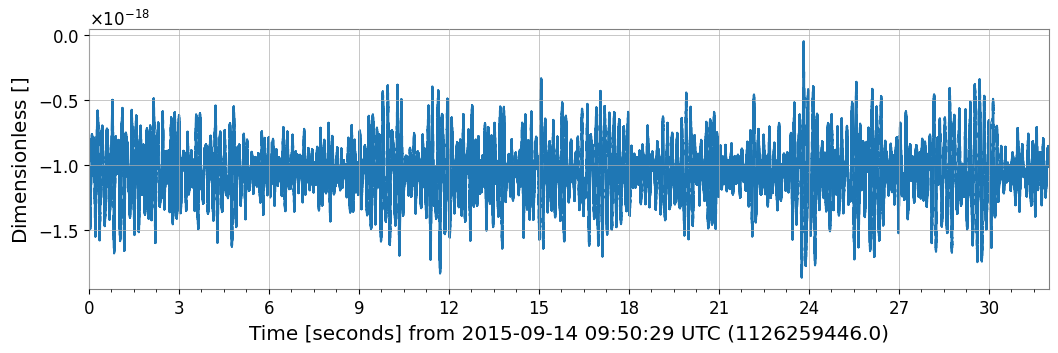

In [168]:
fig1 = strain.plot()

Raw strain versus time

(1e-24, 1e-19)

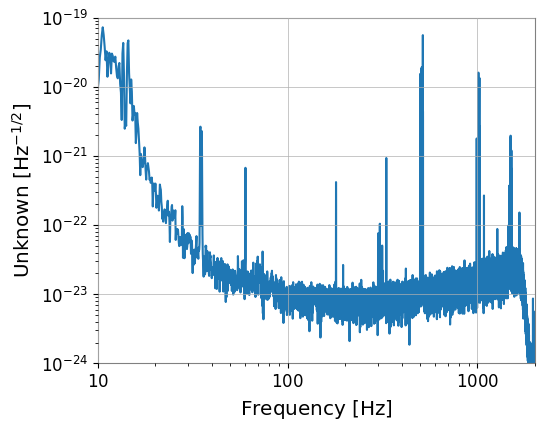

In [169]:
fig2 = strain.asd(fftlength=8).plot()
plt.xlim(10,2000)
plt.ylim(1e-24, 1e-19)

Amplitude spectral density

(1126259462.2, 1126259462.5)

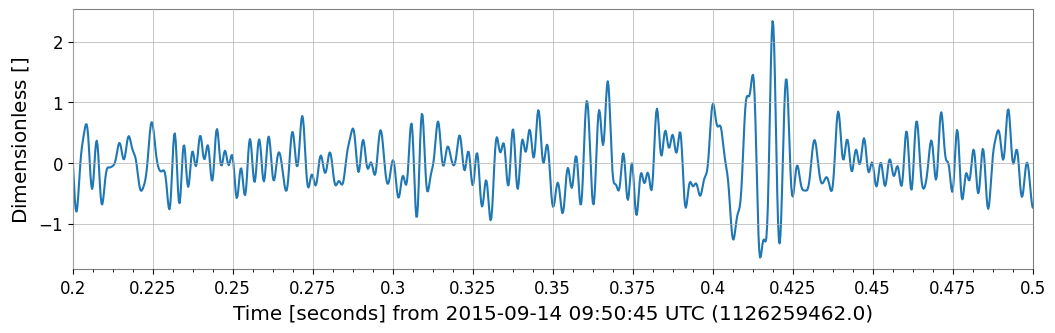

In [170]:
white_data = strain.whiten()
bp_data = white_data.bandpass(30, 400)
fig3 = bp_data.plot()
plt.xlim(t0-0.2, t0+0.1)

Whitened, filtered time series

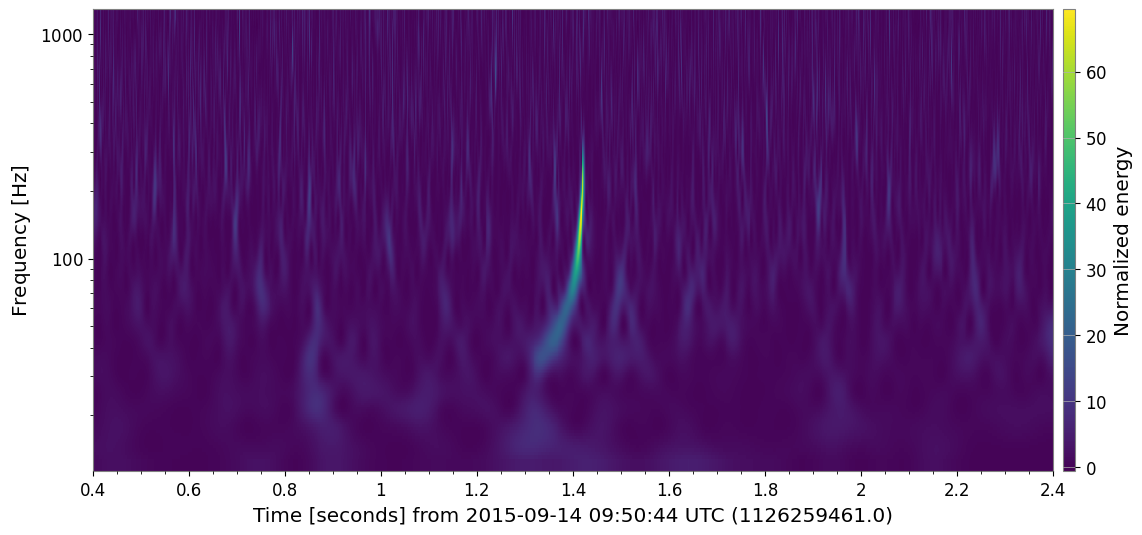

In [171]:
dt = 1  #-- Set width of q-transform plot, in seconds
hq = strain.q_transform(outseg=(t0-dt, t0+dt))
fig4 = hq.plot()
ax = fig4.gca()
ax.grid(False)
ax.set_yscale('log')
try: fig4.colorbar(label="Normalized energy")
except: pass

Q-transform

In [172]:
t0 = 1177008883.4
detector = 'L1'

In [173]:
center = int(t0)  #-- Round GPS time to nearest second
strain = TimeSeries.fetch_open_data(detector, center-16, center+16)
print(strain)

TimeSeries([ 2.27821144e-19,  2.29404831e-19,  2.27110219e-19,
            ..., -5.04574249e-19, -5.01173431e-19,
            -5.09282497e-19]
           unit: dimensionless,
           t0: 1177008867.0 s,
           dt: 0.000244140625 s,
           name: Strain,
           channel: None)


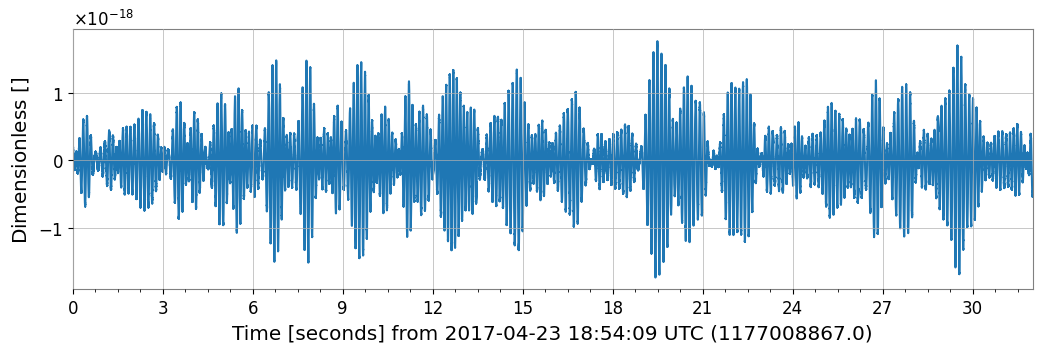

In [174]:
SVT2 = strain.plot()


[2.27821144e-19 2.29404831e-19 2.27110219e-19 2.22176166e-19
 2.23379782e-19 2.19821102e-19 2.17577581e-19 2.24306591e-19
 2.26394444e-19 2.26826683e-19]
[1.17700887e+09 1.17700887e+09 1.17700887e+09 1.17700887e+09
 1.17700887e+09 1.17700887e+09 1.17700887e+09 1.17700887e+09
 1.17700887e+09 1.17700887e+09]
131072
131072
409
4096


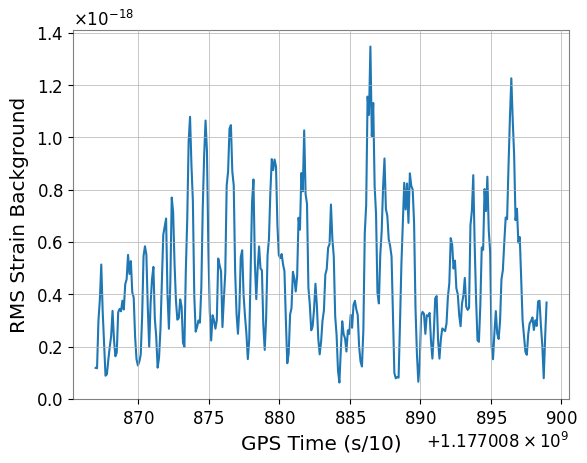

In [175]:
# new added code during lab 6
print(strain.value[:10])
timeTest = strain.times.value[0:10]
print(timeTest)
Strainlength = len(strain.value)
print(Strainlength)
timeLength= len(strain.times.value)
print(timeLength)
averageStrain=[]
seconds=[]
sample_rate = int(strain.sample_rate.value)
newsample_rate = int(strain.sample_rate.value/10)
print(newsample_rate)
print(sample_rate)
#for i in range (0,13100, 1000):
  #average= np.mean(strain.value[i:i+1000])
  #averageStrain.append(average)
  #second = strain.times.value[i:i+1000]
  #seconds.append(second)
#plt.plot(seconds,averageStrain)

rms_background =[]
for i in range(0, len(strain.value), newsample_rate):
  pieceStrain = strain.value[i:i + newsample_rate]
  pieceTime=strain.times.value[i:i+newsample_rate]
  meanrms = np.sqrt(np.mean(pieceStrain**2))
  rms_background.append(meanrms)
  seconds.append(pieceTime[0])
plt.plot(seconds, rms_background)
plt.xlabel("GPS Time (s/10)")
plt.ylabel("RMS Strain Background")
plt.show()

In [179]:
# try to divide RMS strain background into "count" and then graph count vs GPS time
sortStrain= np.sort(strain.value)
print(sortStrain)
strainRange = max(sortStrain) - min(sortStrain)
print(strainRange)
countrange = strainRange/100
print(countrange)
# countrange gave how many count inverval on x axis
# so for x axis it would be from appromimately -1.7 to 1.7 with 100 bins, each bins have a size 3.5e-20
#countStrain = []
#for i in range(0,len(sortStrain)):
#  for j in range(int(max(sortStrain)),int(min(sortStrain))):
step = 0.02
bins = np.arange(0, max(rms_background) + step, step)
counts, bin_edges = np.histogram(rms_background, bins=bins)
for i in range(len(counts)):
    print(f"Interval {bin_edges[i]:.4g} to {bin_edges[i+1]:.4g}: {counts[i]} counts")
# don't know how to find very uique value and fited to a fixed inteval yet, iamtrying to find out online





[-1.73944576e-18 -1.73366051e-18 -1.73349086e-18 ...
  1.76863651e-18  1.77027901e-18  1.77095611e-18]
3.510401869385309e-18
3.5104018693853094e-20


The background noise looks random and doesn't have a particular distribution to fit this background. I don't know the cause of this might it it's because we need to divide the strain by sqrt(Hz) or we need to normalize the strain in order to produce a background with proper distribution.

i actually did some research online, i think the cause is raw infemetry data is dominated by low frequency noise which hides the higher frequency features.

In [ ]:

SVF2 = strain.asd(fftlength=8).plot()
plt.xlim(10,2000)
plt.ylim(1e-24, 1e-19)

In [ ]:
white_data = strain.whiten()
bp_data = white_data.bandpass(30, 400)
SWVT2 = bp_data.plot()
plt.xlim(t0-0.2, t0+0.1)

In [ ]:
# new added code during lab 6
print(white_data[:10])
timeTest = white_data.times.value[0:10]
print(timeTest)
Strainlength = len(white_data.value)
print(Strainlength)
timeLength= len(white_data.times.value)
print(timeLength)
averageStrain=[]
seconds=[]
sample_rate = int(white_data.sample_rate.value)
newsample_rate = int(white_data.sample_rate.value)
print(newsample_rate)
print(sample_rate)

rms_background =[]
for i in range(0, len(white_data.value), newsample_rate):
  pieceStrain = white_data.value[i:i + newsample_rate]
  pieceTime=white_data.times.value[i:i+newsample_rate]
  meanrms = np.sqrt(np.mean(pieceStrain**2))
  rms_background.append(meanrms)
  seconds.append(pieceTime[0])
plt.plot(seconds, rms_background)
plt.xlabel("GPS Time (s)")
plt.ylabel("RMS Strain Background")
plt.show()

In [ ]:
dt = 1  #-- Set width of q-transform plot, in seconds
hq = strain.q_transform(outseg=(t0-dt, t0+dt))
Qseries2 = hq.plot()
ax = fig4.gca()
ax.grid(False)
ax.set_yscale('log')
try: fig4.colorbar(label="Normalized energy")
except: pass

For this project, i will investigate brackground noise in LIGO around the gravitational-wave event GW150914. I will use public data from  the Gravitational Wave Open Science Center. And in the data, strain measures the infinitesimal change in length that associated with the detector measurement. I also used the GWOSC Quickview notebook to dowload and plot the data.

My question is: does the background noise remain statistically consistent across nearby time intervals, and how well does a gaussian distribution with a potentially time dependent mean and standard deviation describe its fluctuations?

for the next 3 labs. I will select several background intervals outside the event and check their data quality, I will compare their time series, frequency spectra and whitened and filtered amplitudes graph. I will compuate the mean and standard deviation in each interval and examine whether extreme fluctuate occur more freqently than a gaussian model would predicts. If not I will try to model the background using other distribution. The same processing will applly to each interval, with fliter edges excluded.
My initial notebook include raw strain graph, a amplitude spectral density graph, a whitened and filtered data plot, and a time freqency map. I will start with dowload 32 second recording and find a longer recording if needed for background comparison.